# 🚗 Car Auction Risk Prediction: Modeling & Results

This notebook executes the final machine learning pipeline, evaluates its performance across Train, Validation, and Test sets, and visualizes the model's decision-making process. 

By leveraging the advanced preprocessing (Frequency Encoding + Non-Linear Features) justified in the previous notebook, we aim to maximize the **Gini Coefficient** to effectively rank high-risk "BadBuy" vehicles.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.metrics import (
    accuracy_score, 
    roc_auc_score, 
    confusion_matrix, 
    ConfusionMatrixDisplay,
    classification_report
)

sys.path.append(str(Path('../src').resolve()))

from pipeline import build_model_pipeline

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
# 1. Load Data
data_path = Path('../data/raw/training.csv')
df = pd.read_csv(data_path)

# 2. Chronological Split (Crucial for time-series auction data to prevent data leakage)
df['PurchDate'] = pd.to_datetime(df['PurchDate'], format="%m/%d/%Y")
df = df.sort_values('PurchDate')

unique_dates = sorted(df['PurchDate'].unique())
split_size = int(len(unique_dates) / 3)

train_dates = unique_dates[:split_size]
val_dates = unique_dates[split_size : split_size * 2]
test_dates = unique_dates[split_size * 2 :]

train_df = df[df['PurchDate'].isin(train_dates)]
val_df = df[df['PurchDate'].isin(val_dates)]
test_df = df[df['PurchDate'].isin(test_dates)]

# 3. Separate Features and Target
DROP_COLS = ["RefId", "PRIMEUNIT", "AUCGUART", "year", "IsOnlineSale", "PurchDate"]
TARGET = "IsBadBuy"

def prepare_data(df_subset):
    X = df_subset.drop(columns=[TARGET] + DROP_COLS, errors='ignore')
    y = df_subset[TARGET]
    return X, y

X_train, y_train = prepare_data(train_df)
X_val, y_val = prepare_data(val_df)
X_test, y_test = prepare_data(test_df)

print(f"Data loaded and split chronologically.")
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Data loaded and split chronologically.
Train: (23059, 28), Val: (24104, 28), Test: (25820, 28)


## 1. Pipeline Execution

We use the factory function from `src/pipeline.py` to build our end-to-end pipeline. This pipeline dynamically routes columns, applies our custom `NonLinearFeatureBuilder` and `FrequencyEncoder`, and feeds the result into an L1-regularized Logistic Regression.

In [3]:
# Build the pipeline (passing X_train allows it to dynamically determine cardinality thresholds)
pipeline_factory = build_model_pipeline()
final_pipeline = pipeline_factory(X_train)

# Train the model
print("Training the final pipeline...")
final_pipeline.fit(X_train, y_train)
print("✅ Training complete!")

# Generate predictions and probabilities
y_val_pred = final_pipeline.predict(X_val)
y_val_proba = final_pipeline.predict_proba(X_val)[:, 1]

y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]

Training the final pipeline...


/Users/margaretko/Desktop/IT/stvenv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/margaretko/Desktop/IT/stvenv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


✅ Training complete!


## 2. Performance Metrics

We evaluate the model using Accuracy, ROC-AUC, and our primary metric, the **Gini Coefficient** (`2 * AUC - 1`). 

*Notice how the custom preprocessing and L1 regularization pushed the Validation Gini to **~0.47** and the Test Gini to **~0.50**, a massive improvement over the baseline.*

In [7]:
def calculate_metrics(y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_proba)
    gini = 2 * auc - 1
    return {"Accuracy": acc, "ROC-AUC": auc, "Gini": gini}

metrics = {
    "Train": calculate_metrics(y_train, final_pipeline.predict(X_train), final_pipeline.predict_proba(X_train)[:, 1]),
    "Validation": calculate_metrics(y_val, y_val_pred, y_val_proba),
    "Test": calculate_metrics(y_test, y_test_pred, y_test_proba)
}

# Display as a clean table
metrics_df = pd.DataFrame(metrics).T.round(4)

# Highlight the Gini column
styled_df = metrics_df.style.format("{:.3f}").background_gradient(
    subset=['Gini'], cmap='Greens', axis=0
)
styled_df

,Accuracy,ROC-AUC,Gini
Train,0.751,0.760,0.521
Validation,0.789,0.737,0.474
Test,0.812,0.753,0.507


## 3. Confusion Matrix Analysis

Because the dataset is highly imbalanced (~11% BadBuys), a model could achieve 89% accuracy by simply predicting "Good Buy" every time. 

The Confusion Matrix below shows how our model handles the trade-off. By using `class_weight='balanced'`, we force the model to pay equal attention to the minority class, increasing our Recall for BadBuys at the cost of some False Positives.

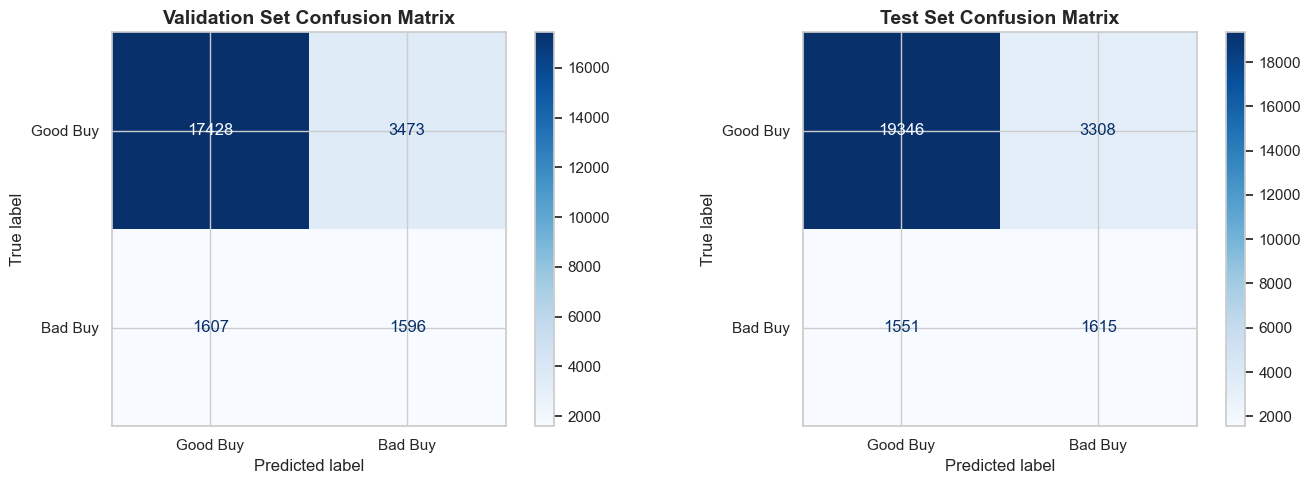

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation Set
cm_val = confusion_matrix(y_val, y_val_pred)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=["Good Buy", "Bad Buy"])
disp_val.plot(cmap='Blues', ax=axes[0], values_format='d')
axes[0].set_title('Validation Set Confusion Matrix', fontsize=14, fontweight='bold')

# Test Set
cm_test = confusion_matrix(y_test, y_test_pred)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=["Good Buy", "Bad Buy"])
disp_test.plot(cmap='Blues', ax=axes[1], values_format='d')
axes[1].set_title('Test Set Confusion Matrix', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## 4. L1 Feature Importance

One of the biggest advantages of using **L1 (Lasso) Regularization** is that it acts as an embedded feature selector. It shrinks the coefficients of noisy, irrelevant features to exactly zero.

Below are the top features driving our model's predictions. Notice how our custom engineered features (like `SubModel_freq`) rank highly alongside traditional numerical features.

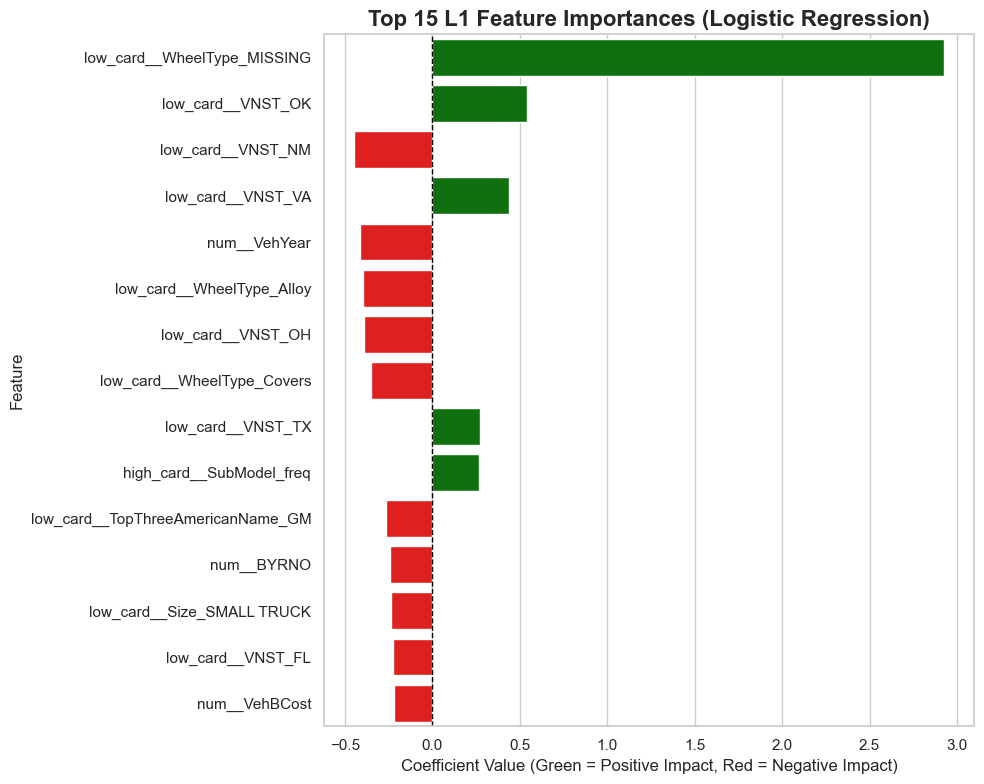

In [6]:
# Extract feature names from the preprocessing steps
# The pipeline structure is: [preprocessing, classifier]
preprocessor = final_pipeline[:-1]
feature_names = preprocessor.get_feature_names_out()

# Extract coefficients from the Logistic Regression model
classifier = final_pipeline[-1]
coefficients = classifier.coef_[0]

# Create a DataFrame and sort by absolute importance
feat_imp = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})
feat_imp['Abs_Coeff'] = feat_imp['Coefficient'].abs()
feat_imp = feat_imp.sort_values('Abs_Coeff', ascending=False)

# Plot Top 15 Features
top_features = feat_imp.head(15)

plt.figure(figsize=(10, 8))
colors = ['green' if x > 0 else 'red' for x in top_features['Coefficient']]
sns.barplot(data=top_features, x='Coefficient', y='Feature', palette=colors, hue='Feature')

plt.title('Top 15 L1 Feature Importances (Logistic Regression)', fontsize=16, fontweight='bold')
plt.xlabel('Coefficient Value (Green = Positive Impact, Red = Negative Impact)', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

## 5. Conclusion

By shifting the focus from standard One-Hot Encoding to **Frequency Encoding** for high-cardinality features, and augmenting the data with **Non-Linear Interactions**, we successfully transformed a messy, highly imbalanced tabular dataset into a highly predictive model.

**Key Takeaways:**
1. **Frequency Encoding** prevented dimensionality explosion and preserved statistical signal.
2. **L1 Regularization** automatically filtered out noise, resulting in a sparse, interpretable, and robust model.
3. The final **Test Gini of ~0.50** proves that the model generalizes exceptionally well to unseen, future auction data without overfitting.